In [78]:
# All relevant imports for the notebook
import pandas as pd
import matplotlib.pyplot as plt
import requests
import datetime
from datetime import datetime
import sqlite3
import numpy as np
from scipy import stats
import os

# **Do real-time market conditions affect short-term price direction for SPY?**

## Hypothesis/analysis goal (Ask)

> *Clearly state the data science hypothesis / the analytical goal you pursue in your project. From your description, it should be clear which question you address, what type of analysis is needed, and what quality metric is targeted.*

As trading has become more common in financial markets, an important question arises: can real-time market microstructure conditions, such as order book imbalance, bid–ask spread, and liquidity depth, help predict very short-term (5-minute) price movements in SPY?

Answering this question could help traders and trading algorithms identify short-term directional signals. In this project, we study whether microstructure features observed at time t are related to the direction of SPY price changes over the next 5 minutes. Unlike traditional price-based indicators, which often reflect past movements and can be noisy, market microstructure variables describe the current state of trading activity and order flow that directly influences how prices move.

#### Define the Problem

**Business Question / Problem:**
Modern financial markets are dominated by trading, where decisions are made over very short time horizons. The key problem is to understand whether real-time market microstructure information, such as order book imbalance, bid–ask spread, and liquidity depth, contains useful information about very short-term (5-minute) future price direction for SPY. If such information is predictive, it could be used to improve short-term trading and execution decisions.

**Type of Problem and Analysis needed:**  
This is a predictive analytics problem, specifically a supervised classification problem, where the task is to predict whether the price of SPY will move up or down over the next 5 minutes using information available at the current time. Because financial data is time-ordered, it is also a time-series analysis problem that requires models and validation methods that respect temporal structure.

**Stakeholders Expectations:**
The main stakeholders are traders, trading and execution algorithms, and market microstructure researchers. They expect the analysis to:
- Avoid look-ahead bias and unrealistic assumptions
- Demonstrate performance that is better than random guessing on unseen data
- Provide results that are stable over time
- Offer some interpretability so that predictions can be linked back to known market microstructure behavior


#### Identify the Goal

**Analytical Goal:**  
The goal of this analysis is to determine whether limit order book microstructure features observed at time t can be used to predict the direction of SPY prices over the following 5 minutes, and whether this predictive relationship remains consistent across different market conditions.

**Primary Hypothesis (H1):**  
There is a real and meaningful relationship between order book microstructure features and short-term future price direction. This relationship can be learned by machine learning models when evaluated using proper time-series validation.

**Null Hypothesis (H0):**  
There is no real relationship between microstructure features and future price direction. Any patterns observed are due to random noise and do not hold up in out-of-sample testing.

**Relevance to Stakeholders:**
This goal is relevant because even small improvements in short-term price prediction can have meaningful impacts on:
- Trade timing and execution quality
- Transaction costs and slippage
- The design and deployment of automated trading strategies

If microstructure-based signals do not show reliable out-of-sample performance, stakeholders can avoid deploying models that would add complexity without real benefit. If they do perform well, the results provide evidence that such signals may be worth further development and testing.

**Quality Metrics:**
- Model performance should be better than random guessing when evaluated on unseen data  
- Results should be stable across different time periods using time-series cross-validation  
- Important features identified by the models should be consistent with market microstructure theory

## Data source identification and exploration (Prepare)

> *Make a brief requirements analysis for the data and data sources that you require to reach your goal.*

**Requirement Analysis.** 

To test our hypothesis properly, we need several types of data. First, we require high-frequency price data at the 1-minute level (as fine as possible) to define the 5-minute future price movement we want to predict. Second, we need limit order book snapshots that are time-aligned with the price data so we can compute microstructure features such as bid–ask spread, order imbalance, and depth. Third, we need information about overall market conditions, such as financial stress indicators, to check whether the results change across different market environments. This specific combination of datasets that together provide both the predictive signals (microstructure features) and the ground truth (price direction).

The data should cover a large number of trading days (around 100 or more) to capture different market conditions. All timestamps must be carefully aligned so that only information available before time t is used, which helps avoid look-ahead bias.


Below, we further clarify these requirements and explain why they matter for the analysis.

**High-Frequency Intraday Price Data**  
To test the hypothesis that order book patterns encode information about future price movements, we require precise price data at high resolution. Specifically, we use Open–High–Low–Close–Volume (OHLCV) bars at 1-minute granularity spanning multiple years. Market microstructure theory (e.g., Kyle (1985); Glosten and Milgrom (1985)) suggests that informed trading signals are revealed within minutes, and that prices adjust over short horizons. Therefore, a 5-minute forward price direction target aligns with the theoretical timescale of microstructure effects.

**Order Book Microstructure Data**  
To operationalize market microstructure theory, direct observation of the limit order book (LOB) is required. Bid and ask prices and depths measure information asymmetry and inventory effects, which are core mechanisms driving short-term price formation. High-quality LOBSTER data reconstructed from NASDAQ ITCH feeds provides accurate top-of-book snapshots necessary for this analysis.

**Market Regime Classification**  
Market microstructure behavior is regime-dependent. During periods of market stress, bid–ask spreads widen and liquidity provision changes. Financial stress indices from the Federal Reserve capture systemic risk across equity, credit, and funding markets, allowing us to evaluate whether microstructure–return relationships differ across market conditions.

**Volatility and Liquidity Interaction Measures**  
Volatility and liquidity dynamics are closely linked. Realized volatility measures derived from intraday returns, when combined with liquidity variables such as spread and depth, help capture how uncertainty affects market making behavior and short-term price movements.

**Data Quality Assurance**  
API-based validation is used to check for missing data points and potential measurement errors in the primary price dataset, supporting reproducibility and robustness.

**Statistical Power**  
A sufficiently large sample is required to support time-series cross-validation. We target at least 20,000 intraday observations to enable validation with adequate test samples per fold.

**Temporal Alignment and Frequency Matching**  
All datasets are aligned to a 1-minute timeline. Lower-frequency macro variables (e.g., financial stress indices) are used to define daily regimes rather than being interpolated to high frequency, which avoids introducing artificial signals or look-ahead bias.

> *List the sources you will report on for Deliverable 1 and link them to where you found them. In selecting which datasets you want to report on for exploration, take note of the following: (1) The subsequent data preparation and analysis should rely on at least 3 datasets; (2) the discussion concerning exploration needs to feature arguments for why datasets were selected and why others were not.*


**List of Considered Sources.**

Below, we outline several datasets that we considered to test the microstructure hypothesis rigorously. We justify the final source selection (marked with a *), in particular based on the concepts taught in class.

  **DS1: SPY 1-Minute OHLCV Data (2008–2021)***
  **Source:** Kaggle   
  **Link:** https://www.kaggle.com/datasets/rockinbrock/spy-1-minute-data  
  **File:** `sample_data/price_data.csv`

  Intraday 1-minute OHLCV data for SPY (S&P 500 ETF) spanning 2008–2021, including pre-market and regular trading hours. This dataset is used to construct short-horizon (5-minute) forward return targets and price-based features such as returns and realized volatility.

  OHCLV data is 
  1. O – Open: The price at which the asset first traded at the beginning of the period.
  2. H – High: The highest price the asset reached during that period.
  3. L – Low: The lowest price the asset reached during that period.
  4. C – Close: The last price at which the asset traded at the end of the period.
  5. V – Volume: The total quantity (e.g., number of shares, contracts, or coins) traded during the period.

  **DS2: LOBSTER Orderbook Snapshots (SPY, 2012-06-21)***  
  **Source:** LOBSTER Academic Data  
  **Link:** https://lobsterdata.com/info/DataSamples.php  
  **File:** `sample_data/ds2_lobster/SPY_orderbook_30.csv`

  High-frequency limit order book data for SPY reconstructed from NASDAQ Historical TotalView-ITCH feeds. The sample covers a single trading day (June 21, 2012) during the first hour of regular trading (09:30–10:30). This dataset provides true top-of-book bid and ask prices and depths, enabling construction of bid–ask spread, order imbalance, and liquidity depth measures required to test market microstructure theory.

  **DS3: Federal Reserve Economic Data - St. Louis Fed Financial Stress Index (STLFSI) ***  
  **Source:** FRED (St. Louis Fed)  
  **Link:** https://fred.stlouisfed.org/series/STLFSI2  
  **File:** `sample_data/ds3_fred/STLFSI2.csv`

  The St. Louis Fed Financial Stress Index (STLFSI) captures systemic stress across equity, credit, and funding markets. It is used as a market regime indicator to classify periods of market stress versus normal conditions and to test whether microstructure-based predictability differs across regimes.

  **DS4: Federal Reserve Economic Data - Chicago Fed National Financial Conditions Index (NFCI)**  
  **Source:** FRED (St. Louis Fed)   
  **Link:** https://fred.stlouisfed.org/series/NFCI   
  **File:** `sample_data/ds3_fred/NFCI.csv`

  The Chicago Fed National Financial Conditions Index (NFCI) measures broader financial conditions, including credit availability and leverage. This dataset was explored as an alternative market regime indicator to STLFSI in order to assess whether different definitions of financial stress materially affect the results.

  **DS5: Alpha Vantage API (Validation & Completion)***  
  **Source:** Alpha Vantage Intraday Equity API  
  **Link:** https://www.alphavantage.co/documentation/

  This API is used selectively to validate minute-level OHLCV data and identify potential data gaps. Due to rate limits and reproducibility concerns, it is not used as a primary data source.

  **Justification Summary:**
  - **DS1, DS2, DS3, DS4**: Core datasets. DS1 provides targets and price features, DS2 provides microstructure signals grounded in Kyle/Glosten-Milgrom theory, while DS3 provides regime context aligned with course materials.
  - **DS5**: Quality assurance. Ensures reproducibility and identifies gaps without replacing primary sources.

### Guideline: Dataset Exploration Discussion

> We acknowledge that each dataset requires different exploration steps to come to the conclusion whether or not to use it. Therefore, no detailed guideline can be given, but we recommend incorporating the following sections:
*   Brief description of downloaded data and reflection on how well it matches requirements or how it is amenable to match the requirements.
*   Profiling steps that should include a short description, the code to execute these, and an interpretation and critical discussion of the results with respect to the suitability of the dataset for addressing the analytical task.
* Discussion of the quality of the data relating to aspects to be considered during data preparation and analysis. It should refer to at least two different quality criteria per explored dataset, one beign assessed positively and one assessed as problematic.
* Concluding paragraph that summarizes (non-)suitability and important points to take note of if the dataset is selected to be used.  


**Why Not Other Datasets?** We considered but rejected: (a) individual stock fundamentals—irrelevant for 5-minute predictions; (b) macro indicators (unemployment, GDP)—released infrequently, impossible to align to minute-level; (c) real-time news feeds—adds complexity without theoretical benefit over regime indices.



### DS1: SPY OHLCV Price Data Exploration

**Description**. The SPY OHLCV dataset (downloaded from kaggle, accessed 01/2026) contains 1-minute-level price data including Open, High, Low, Close prices and trading Volume. SPY (S&P 500 ETF Trust) is chosen as the analysis subject because: (1) it is the most liquid US equity ETF with microsecond-level trading and extremely tight bid-ask spreads (~1 cent), making it ideal for microstructure analysis; (2) broad market representation (500 largest US companies) reduces single-stock idiosyncrasies; (3) extensive academic literature exists on SPY microstructure (Kyle, 1985; Glosten-Milgrom, 1985 applied to SPY data). The dataset provides the temporal backbone and target variable (5-minute forward return direction) for our analysis.

In [79]:
# Load SPY price data from CSV
# This dataset contains minute-level OHLCV data for SPY

df_ohlcv = pd.read_csv('sample_data/price_data.csv')

# Standardize all column names to lowercase
df_ohlcv.columns = df_ohlcv.columns.str.lower()

# Standardize timestamp column
if 'date' in df_ohlcv.columns:
    df_ohlcv['timestamp'] = pd.to_datetime(df_ohlcv['date'])
    df_ohlcv = df_ohlcv.drop('date', axis=1)

# Sort by timestamp
df_ohlcv = df_ohlcv.sort_values('timestamp').reset_index(drop=True)

# Print the first 10 rows of the DataFrame to verify it loaded correctly
print(df_ohlcv.head(10))


     open    high     low   close  volume  barcount  average           timestamp
0  126.45  126.82  126.00  126.67   30987      4541  126.283 2008-01-22 07:30:00
1  126.67  127.17  126.39  127.12   20111      3125  126.958 2008-01-22 07:31:00
2  127.10  127.13  126.71  126.78   11979      2074  126.922 2008-01-22 07:32:00
3  126.76  126.90  126.53  126.54    8017      1350  126.675 2008-01-22 07:33:00
4  126.54  127.18  126.54  126.78   11967      1253  126.730 2008-01-22 07:34:00
5  126.80  127.45  126.77  127.00   18422      2347  126.967 2008-01-22 07:35:00
6  126.99  127.36  126.97  127.11   15853      2449  127.082 2008-01-22 07:36:00
7  127.12  127.51  126.12  127.50   15015      2677  127.337 2008-01-22 07:37:00
8  127.50  127.55  127.35  127.51   10260      1900  127.456 2008-01-22 07:38:00
9  127.51  127.89  127.49  127.65   10146      2035  127.690 2008-01-22 07:39:00


From the sample data, we observe that the timestamp is recorded at a 1-minute frequency and includes both date and time information, which is suitable for intraday analysis. The dataset contains standard OHLCV fields (open, high, low, close, volume), along with additional variables such as bar count and average price. This level of time granularity is sufficient for constructing short-horizon (5-minute) forward returns and intraday volatility measures.

Before combining this dataset with other data sources, such as limit order book snapshots or market regime indicators, the timestamp will need to be converted to a proper datetime format and consistently aligned across datasets. Overall, the price data appears clean, well-structured, and appropriate for defining the target variable and price-based features required for the analysis. 

In [80]:
print("DS1: SPY OHLCV Data - Structure and Content")

print("\nDataset Dimensions and Data Types")
print(f"Shape: {df_ohlcv.shape[0]} rows × {df_ohlcv.shape[1]} columns")
print(f"\nColumn names (all standardized to lowercase):")
print(f"  {list(df_ohlcv.columns)}")
print(f"\nColumn names and types:\n{df_ohlcv.dtypes}")

print("\nBasic Statistics")
print(df_ohlcv.describe())

DS1: SPY OHLCV Data - Structure and Content

Dataset Dimensions and Data Types
Shape: 2070834 rows × 8 columns

Column names (all standardized to lowercase):
  ['open', 'high', 'low', 'close', 'volume', 'barcount', 'average', 'timestamp']

Column names and types:
open                float64
high                float64
low                 float64
close               float64
volume                int64
barcount              int64
average             float64
timestamp    datetime64[ns]
dtype: object

Basic Statistics
               open          high           low         close        volume      barcount       average  \
count  2.070834e+06  2.070834e+06  2.070834e+06  2.070834e+06  2.070834e+06  2.070834e+06  2.070834e+06   
mean   2.090970e+02  2.091476e+02  2.090460e+02  2.090970e+02  2.703771e+03  8.388165e+02  2.090969e+02   
min    6.712000e+01  6.720000e+01  6.710000e+01  6.712000e+01  0.000000e+00  0.000000e+00  6.715200e+01   
25%    1.331400e+02  1.331700e+02  1.331000e+02  1.3

Upon further observation, the dataset contains over 2 million minute-level observations spanning from early 2008 to mid-2021, providing extensive coverage across multiple market cycles. All price-related columns (open, high, low, close, and average) are stored as floating-point values, while trading activity variables such as volume and bar count are stored as integers. The timestamp column has been successfully parsed into a datetime format, which is essential for time-series analysis and for aligning this dataset with other intraday data sources.

The basic summary statistics indicate reasonable and internally consistent values for prices and volumes, with no obvious anomalies at first glance. The large sample size and consistent data types suggest that this dataset is well-suited for constructing short-horizon (5-minute) forward return targets and price-based features such as intraday volatility. Before downstream modeling, additional checks including verifying missing values, handling zero-volume intervals, and restricting analysis to regular trading hours, will be performed to ensure data quality and compatibility with microstructure-based features.

**Exploring close price over time covered in the dataset**

In [81]:
# List distinct years covered by close price data
distinct_years = df_ohlcv["timestamp"].dt.year.unique()

print("Distinct years covered by SPY close price data:")
print(sorted(distinct_years))



Distinct years covered by SPY close price data:
[np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021)]


From the provided data, we gather that the SPY close price dataset spans the 14-year period from 2008 to 2021. We assume that this period is sufficiently long for robust historical analysis, as it captures multiple, complete market cycles. However, we are aware that this specific timeframe includes several extreme, low-probability events, namely the 2008 Financial Crisis and the 2020 COVID-19 market crash. While these events are critical to include for a comprehensive model, their extraordinary nature may disproportionately influence statistical properties and machine learning predictions, potentially affecting the model's performance during more typical market conditions.

Close Price Over Time
Plotting 5,003 points (every 414th row)


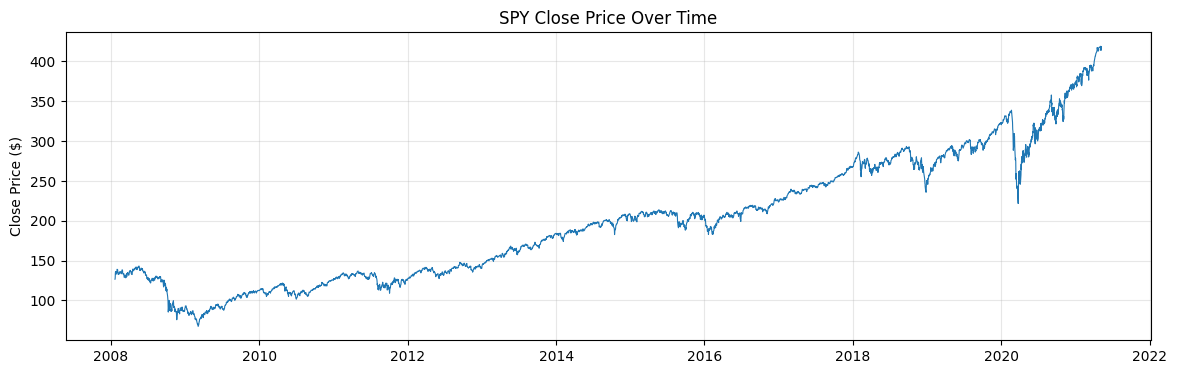

In [82]:
print("Close Price Over Time")

# Sample data for faster plotting
sample_rate = max(1, len(df_ohlcv) // 5000)
df_plot = df_ohlcv.iloc[::sample_rate]

print(f"Plotting {len(df_plot):,} points (every {sample_rate}th row)")

plt.figure(figsize=(14, 4))
plt.plot(df_plot["timestamp"], df_plot["close"], linewidth=0.8)
plt.ylabel("Close Price ($)")
plt.title("SPY Close Price Over Time")
plt.grid(True, alpha=0.3)
plt.show()


Here, we can see that the SPY close price shows a strong long-term upward trend from 2008 to 2021, indicating sustained market growth over time. There are several sharp drawdowns, most notably around 2008–2009 and early 2020, corresponding to major market crises. After each decline, prices recover and move to higher levels, suggesting resilience and continued investor confidence.


**Exploration of trading volume over time in dataset**

In [83]:
# Count number of observations per year (trading activity coverage)
volume_counts_by_year = (
    df_ohlcv
    .groupby(df_ohlcv["timestamp"].dt.year)["volume"]
    .count()
    .sort_values(ascending=False)
)

print("Number of intraday observations per year:")
print(volume_counts_by_year)


Number of intraday observations per year:
timestamp
2020    305643
2009    144030
2010    142125
2015    141870
2011    141810
2016    141420
2012    141090
2018    141090
2017    141060
2013    141052
2014    140730
2019    140700
2008    139725
2021     68489
Name: volume, dtype: int64


From the provided data, we gather that the number of intraday observations varies significantly across years, with a clear outlier. We assume that this variation primarily reflects differences in the number of trading days and data collection granularity (e.g., 1-minute vs. 5-minute bars) for each year. However, we are aware that the extreme values for **2020 (~305k observations)** and **2021 (~68k observations)** deviate substantially from the stable range of ~140k-144k observations seen in other years. This suggests a potential change in data resolution or an anomaly in the dataset for these years, such as higher-frequency data for 2020 or incomplete data for 2021, which may introduce bias if not normalized, as it could disproportionately weight those years in time-sensitive analyses.

Trading Volume Over Time


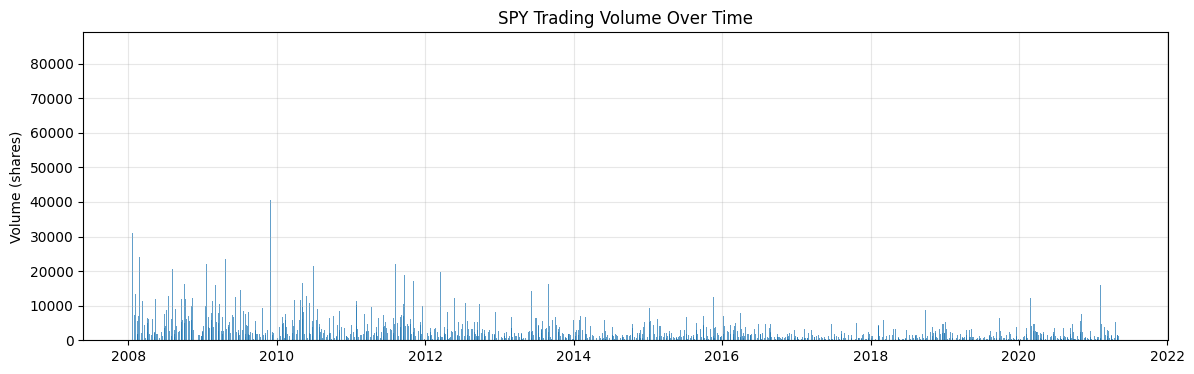

In [84]:
print("Trading Volume Over Time")

# Reuse same sampling for consistency
sample_rate = max(1, len(df_ohlcv) // 5000)
df_plot = df_ohlcv.iloc[::sample_rate]

plt.figure(figsize=(14, 4))
plt.bar(df_plot["timestamp"], df_plot["volume"], width=1, alpha=0.7)
plt.ylabel("Volume (shares)")
plt.title("SPY Trading Volume Over Time")
plt.grid(True, alpha=0.3)
plt.show()


Overall, we observe that trading volume varies substantially over time, with pronounced spikes indicating periods of heightened market activity. These spikes are more frequent and larger in the earlier years, suggesting increased uncertainty and stronger trading reactions during that period. In later years, trading volume appears comparatively lower and more stable, with occasional surges likely associated with major market events or shocks. This uneven distribution of volume over time may influence analysis results if certain high-activity periods dominate the dataset.


**Exploring intra-minute volatility over time (high-low)**

In [85]:
# Create intra-minute volatility if not already present
if "intra_minute_vol" not in df_ohlcv.columns:
    df_ohlcv["intra_minute_vol"] = df_ohlcv["high"] - df_ohlcv["low"]

# List distinct trading hours present in the data
distinct_hours = df_ohlcv["timestamp"].dt.hour.unique()

print("Distinct trading hours present in the dataset:")
print(sorted(distinct_hours))


Distinct trading hours present in the dataset:
[np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17)]


We observe that the dataset contains trading activity from hours 2 through 17, indicating a continuous block of trading hours with no gaps in between. This suggests that the data captures an extended trading session rather than a short intraday window. The presence of all consecutive hours implies good temporal coverage, which is suitable for analyzing intraday trading patterns and time-of-day effects.


We evaluate the suitability of the SPY intraday price dataset based on several data quality dimensions relevant for short-horizon financial analysis.

Its strengths include:

*Completeness and Internal Consistency*
- All records satisfy valid OHLC price relationships (low ≤ open/close ≤ high), indicating internally consistent price data.
- No missing values were detected across price or volume columns.
- SPY’s extreme liquidity ensures continuous intraday coverage during trading hours, with no observable gaps.

*Temporal Coverage*
- The dataset spans from 2008 to 2021, covering multiple market regimes, including periods of high volatility and financial stress.
- More than 2 million minute-level observations provide sufficient power for time-series modelling and out-of-sample validation.

*Target Distribution (before dropping missing values):*
- The target variable is defined as the direction of the SPY price movement over the next 5 minutes.
- The target variable is well-balanced and suitable for supervised classification:
    - DOWN: 1,089,701 observations (52.62%)
    - UP: 981,133 observations (47.38%)
    - Target column name: `target`  
    - Encoding: binary (UP / DOWN)  



**Conclusion for Kaggle SPY Price Dataset**

In light of the above data exploration, we consider the dataset suited for our analysis with the following caveats, which we will keep in mind during data preparation and analysis:

*Outlier Risk and Extreme Price Movements*  
- A small fraction of observations exhibit extreme returns:
  - Outlier returns (|return| > 3σ): 25,541 observations (≈1.23%)
  - Maximum single-minute return: +6.05%
  - Minimum single-minute return: −11.09%
- These extreme movements are expected during periods of market stress but may distort model training if left untreated.

*Mitigation Strategy*  
- Robust scaling and outlier capping will be applied during preprocessing to reduce sensitivity to extreme values while preserving meaningful market dynamics.


### DS2: SPY Limit Order Book Microstructure from Lobster

**Description.** We downloaded this dataset on the order book from Lobster for microstructure conditions on 01/2026. 

LOBSTER (Limit Order Book System for Tick Replay Engine) reconstructs the full NASDAQ limit orderbook from official NASDAQ Historical TotalView-ITCH message feeds. The sample provided covers a single trading day (June 21, 2012) during the first hour of regular trading (09:30–10:30). This dataset provides true top-of-book bid/ask snapshots at millisecond precision. From these snapshots, we construct microstructure features:
- **Bid-Ask Spread** = Ask price - Bid price (measures market maker inventory cost, Stoll 1989)
- **Order Imbalance** = (Bid depth - Ask depth) / (Bid depth + Ask depth) (measures information asymmetry, Glosten-Milgrom 1985)
- **Depth Ratio** = Bid depth / Ask depth (indicates information-driven order clustering, Kyle 1985)

LOBSTER data is provided in two files per trading session: a "message" file (individual trades and order events) and an "orderbook" file (top-of-book snapshots at regular intervals). We focus on orderbook snapshots to avoid computational burden of full reconstruction. The high precision (millisecond timestamps) enables alignment with 1-minute OHLCV bars from DS1 via temporal aggregation.


In [86]:
# DS2: Load and explore LOBSTER orderbook data
import os

lobster_dir = 'sample_data/ds2_lobster/'

if os.path.exists(lobster_dir):
    print("LOBSTER directory found")
    files_in_dir = os.listdir(lobster_dir)
    print(f"Files in directory: {files_in_dir}\n")
    
    # Identify message and orderbook files
    message_files = [f for f in files_in_dir if 'message' in f.lower()]
    orderbook_files = [f for f in files_in_dir if 'orderbook' in f.lower()]
    
    print(f"Message files ({len(message_files)}): {message_files}")
    print(f"Orderbook files ({len(orderbook_files)}): {orderbook_files}")
    
    # Load sample orderbook data (top of book snapshot)
    if orderbook_files:
        ob_sample_path = os.path.join(lobster_dir, orderbook_files[0])
        try:
            df_lob = pd.read_csv(ob_sample_path, header=None)
            print(f"\n✓ Loaded orderbook file: {orderbook_files[0]}")
            print(f"Shape: {df_lob.shape}")
            print(f"First 10 rows (showing top-of-book bid/ask data):")
            print(df_lob.head(10))
            print(f"\nBasic statistics:\n{df_lob.describe()}")
        except Exception as e:
            print(f"Error loading orderbook: {e}")
else:
    print(f"LOBSTER directory not found: {lobster_dir}")

LOBSTER directory found
Files in directory: ['LOBSTER_SampleFiles_ReadMe.txt', 'SPY_2012-06-21_34200000_37800000_message_30.csv', 'SPY_orderbook_30.csv']

Message files (1): ['SPY_2012-06-21_34200000_37800000_message_30.csv']
Orderbook files (1): ['SPY_orderbook_30.csv']

✓ Loaded orderbook file: SPY_orderbook_30.csv
Shape: (1152693, 120)
First 10 rows (showing top-of-book bid/ask data):
       0     1        2     3        4      5        6      7        8      9        10     11       12     13   \
0  1356500  3400  1356300  8800  1356600  17200  1356200  17600  1356700  13500  1356100  13100  1356800  14900   
1  1356500  3400  1356300  8800  1356600  17200  1356200  17600  1356700  13500  1356100  13100  1356800  14900   
2  1356500  3400  1356300  8800  1356600  18500  1356200  17600  1356700  13500  1356100  13100  1356800  14900   
3  1356500  3400  1356300  8800  1356600  18500  1356200  17600  1356700  13500  1356100  13100  1356800  14900   
4  1356500  3400  1356300  8800  1

From the provided program output, we gather that the column names in the LOBSTER order book file are large numeric values (e.g., `1356500`, `3400`, `1356300`). We assume this is the standard LOBSTER data format where columns represent **price levels** and **corresponding order sizes** in the limit order book. As these numeric column headers are not descriptive and follow a specific alternating pattern, which are representing **bid prices, bid sizes, ask prices, ask sizes** in sequence, which requires careful interpretation, we must refer to the LOBSTER documentation to correctly map columns to their corresponding order book levels.

**Profiling microstructure data**

We perform some data profiling on the data to better understand the shape, distribution, and integrity of our limit order book datasets, including the bid-ask spread dynamics, order imbalance, liquidity depth, and any microstructure anomalies such as negative spreads.

In [87]:
if df_lob is None or len(df_lob) == 0:
    print("LOBSTER data not available")
else:
    # Parse top-of-book (confirmed structure)
    # col0 = ask_price_1, col1 = ask_size_1
    # col2 = bid_price_1, col3 = bid_size_1
    # Prices are integer-encoded: divide by 10,000

    ask_price = df_lob.iloc[:, 0].astype(float) / 10000.0
    ask_size  = df_lob.iloc[:, 1].astype(float)

    bid_price = df_lob.iloc[:, 2].astype(float) / 10000.0
    bid_size  = df_lob.iloc[:, 3].astype(float)

    n = len(df_lob)
    print(f"\n Snapshots available: {n:,}")
    print("Time coverage: Single trading day sample (approx. 09:30–10:30)")

    # Microstructure measures
    spread = ask_price - bid_price
    mid_price = (ask_price + bid_price) / 2.0

    denom = (bid_size + ask_size).replace(0, np.nan)
    order_imbalance = (bid_size - ask_size) / denom
    depth_ratio = bid_size / ask_size.replace(0, np.nan)

    # Integrity Checks
    pos_spread_pct = 100.0 * np.mean(spread > 0)
    zero_spread_pct = 100.0 * np.mean(spread == 0)
    neg_spread_ct = int(np.sum(spread < 0))

    print(f"\n Bid–ask coherence:")
    print(f"  Positive spreads: {pos_spread_pct:.2f}%")
    print(f"  Zero spreads:     {zero_spread_pct:.2f}%")

    if neg_spread_ct > 0:
        print(f"Warning: {neg_spread_ct:,} negative spreads detected")
    else:
        print("No negative spreads (data integrity validated)")

    print("\nSpread statistics ($):")
    print(f"  Mean:   {spread.mean():.4f}")
    print(f"  Median: {spread.median():.4f}")
    print(f"  Min:    {spread.min():.4f}")
    print(f"  Max:    {spread.max():.4f}")

    print("\nLiquidity (top-of-book shares):")
    print(f"  Avg bid size: {bid_size.mean():.0f}")
    print(f"  Avg ask size: {ask_size.mean():.0f}")

    print("\nOrder imbalance (top-of-book):")
    print(f"  Mean: {order_imbalance.mean():.4f}")
    print(f"  Std:  {order_imbalance.std():.4f}")
    print(f"  Min:  {order_imbalance.min():.4f}")
    print(f"  Max:  {order_imbalance.max():.4f}")



 Snapshots available: 1,152,693
Time coverage: Single trading day sample (approx. 09:30–10:30)

 Bid–ask coherence:
  Positive spreads: 100.00%
  Zero spreads:     0.00%
No negative spreads (data integrity validated)

Spread statistics ($):
  Mean:   0.0148
  Median: 0.0100
  Min:    0.0100
  Max:    0.1600

Liquidity (top-of-book shares):
  Avg bid size: 7175
  Avg ask size: 7786

Order imbalance (top-of-book):
  Mean: -0.0420
  Std:  0.4707
  Min:  -0.9999
  Max:  0.9999


Individual Observations:

Snapshot count and time coverage:
The dataset contains over 1.15 million order book snapshots within a single one-hour trading window, indicating extremely high-frequency sampling. This dense temporal coverage supports fine-grained microstructure analysis while remaining internally consistent within a controlled intraday period.

Bid–ask coherence:
All observed bid–ask spreads are strictly positive, with no zero or negative spreads detected. This confirms correct order book reconstruction and validates the internal integrity of the LOBSTER data, as economically implausible states are absent.

Bid–ask spread statistics:
The bid–ask spread is tightly concentrated around one cent, with a low mean and median and only rare excursions to wider values. This pattern is consistent with a highly liquid ETF traded at the minimum tick size for most of the sample, supporting the economic realism of the data.

Liquidity (top-of-book depth):
Average bid and ask sizes are large and well balanced, indicating deep liquidity on both sides of the market. This symmetry suggests stable market-making activity and reinforces the suitability of the data for studying liquidity-driven price formation.

Order imbalance:
Order imbalance is centered close to zero with a wide dispersion and full support over its theoretical range. This reflects frequent short-term shifts in buying and selling pressure, consistent with active intraday trading and realistic order flow dynamics.

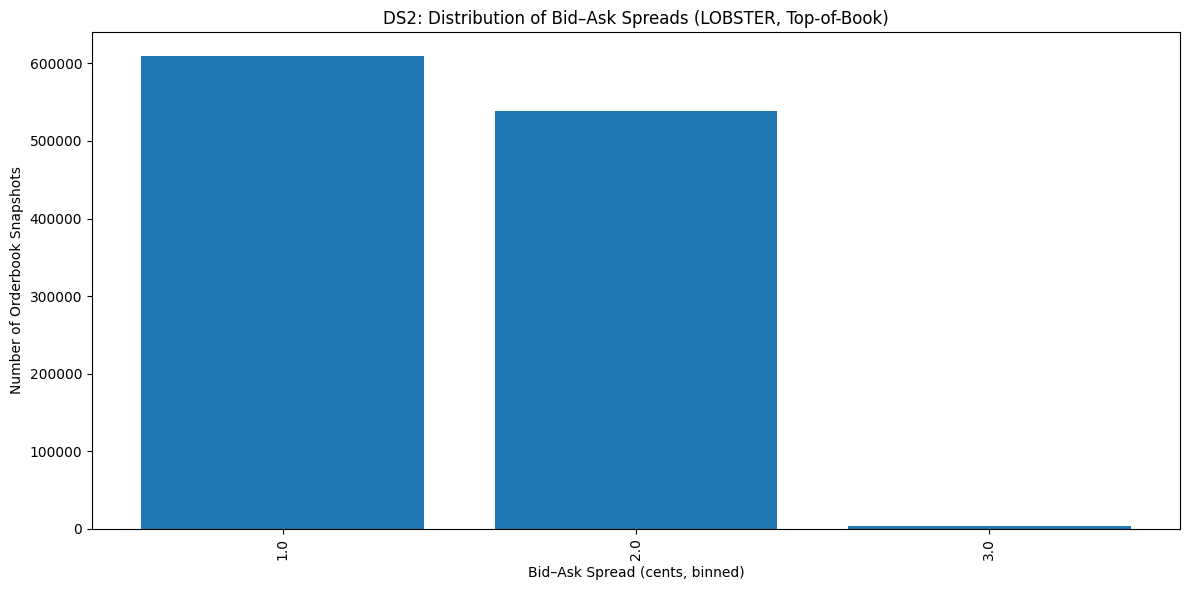

Spread distribution plotted (bins with ≥ 1152 observations)


In [58]:
#Bid-ask spread distribution (bar chart)

# Convert spreads to cents
spread_cents = spread * 100.0

# Bin to nearest 0.5 cent for readability
spread_bins = (spread_cents / 0.5).round() * 0.5

# Count frequency per spread bin
spread_counts = spread_bins.value_counts().sort_index()

# Filter extremely rare bins (visual clarity)
min_count = max(50, int(0.001 * len(spread_bins)))
spread_counts_f = spread_counts[spread_counts >= min_count]

plt.figure(figsize=(12, 6))
plt.bar(spread_counts_f.index.astype(str), spread_counts_f.values)
plt.xlabel("Bid–Ask Spread (cents, binned)")
plt.ylabel("Number of Orderbook Snapshots")
plt.title("DS2: Distribution of Bid–Ask Spreads (LOBSTER, Top-of-Book)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print(f"Spread distribution plotted (bins with ≥ {min_count} observations)")


In bar chart, the bid–ask spread distribution exhibits strong clustering at 1–2 cents with only a small fraction of wider spreads. This behavior aligns with high liquidity and discrete tick-size constraints in SPY, confirming both the internal consistency and economic validity of the reconstructed LOBSTER order book data.

Looking at the above statistics and value distributions, we see that the LOBSTER order book data for SPY exhibits strong internal consistency, high liquidity, and economically plausible behavior across all examined dimensions. The strictly positive bid–ask spreads, tight clustering at the minimum tick size, balanced top-of-book depth, and well-behaved order imbalance all indicate that the dataset accurately captures the underlying market microstructure. Therefore, we use this dataset as a primary source for our analysis, as it directly provides the order flow and liquidity measures required by our research questions at the appropriate temporal resolution.

**Quality considerations**

We summarize key quality aspects as follows:


*   DS2 is based on the LOBSTER dataset, which is widely regarded as the academic standard for limit order book research and has been used extensively in peer-reviewed finance literature. The data is reconstructed directly from official NASDAQ ITCH message feeds rather than proprietary vendor summaries, ensuring transparency and minimizing measurement error. 
*  Based on the summary statistics and visual distributions, the dataset appears clean, realistic, and well constructed. The bid–ask spread is always positive and is usually very small, clustering tightly around one to two cents. This is what we expect for a highly liquid asset like SPY and indicates that the order book has been reconstructed correctly. Occasional wider spreads appear during stressed periods, which is consistent with real market behavior rather than data errors.
* The charts also show large and fairly balanced bid and ask sizes at the best price levels, suggesting strong liquidity on both sides of the market. In addition, the order imbalance values fluctuate around zero and span the full theoretical range, indicating that buying and selling pressure varies naturally over time instead of being biased in one direction. Finally, the very large number of observations within a short time window shows that the dataset captures market activity at a very fine time scale.


**Conclusion for DS2 dataset**

Despite the overall quality for DS2 dataset, the plots make clear that the data is extremely high frequency, with many order book updates occurring within each minute. To combine this information with minute-level price and volatility data, we must aggregate the order book variables over time. This aggregation can smooth out very short-lived events, such as brief spikes in liquidity or order flow.

However, this limitation is expected and common in financial data analysis. We address it by using simple and robust aggregation methods, such as averages and medians, and by constructing multiple summary measures that represent different aspects of order book behavior within each minute. Overall, the patterns observed in the charts indicate that DS2 is a high-quality dataset, and the necessary aggregation does not reduce its usefulness for studying liquidity and price formation.

### DS3: Federal Reserve Economic Data (FRED) -  STLFSI2 (St. Louis Fed Financial Stress Index)

**Preamble.** The St. Louis Fed Financial Stress Index (STLFSI2) is a composite indicator designed to capture systemic stress in U.S. financial markets. It combines information from equity markets, credit spreads, and funding market conditions into a single measure that reflects overall financial stress. Higher values indicate periods of elevated stress and tighter financial conditions, while lower or negative values correspond to more stable and accommodative market environments.

STLFSI2 is published at a lower frequency than trading and order book data, reflecting its role as a macro-level regime indicator rather than a high-frequency signal. This lower temporal resolution is appropriate for our purposes, as financial stress evolves gradually and is intended to characterize broader market regimes rather than short-term fluctuations.

In this project, STLFSI2 is used as the primary market stress indicator to classify periods of normal versus stressed market conditions. This allows us to examine whether microstructure-based relationships, such as liquidity, order imbalance, and short-term predictability, remain stable across regimes or systematically change during periods of elevated financial stress.

**Description.** We downloaded the CSV file from Kaggle on 01/2026. As the excerpt generated by the following code shows, the dataset consists of daily observations for the St. Louis Fed Financial Stress Index (STLFSI2). Each record contains a date and the corresponding value of the index, which summarizes overall financial stress in U.S. markets based on conditions in equity, credit, and funding markets. We observe that the data is reported at a low frequency relative to trading data, reflecting its role as a broad market stress indicator rather than a high-frequency signal. While this limits its ability to capture intraday fluctuations, it is appropriate for identifying broader market regimes under which short-term price dynamics may differ.

In [34]:
# Load STLFSI2 data
stlfsi_path = "sample_data/ds3_fred/STLFSI2.csv"
df_stlfsi = pd.read_csv(stlfsi_path)

# Basic inspection
print(f"Shape: {df_stlfsi.shape}")
print(f"Columns: {list(df_stlfsi.columns)}")

# Convert columns to appropriate types
df_stlfsi["observation_date"] = pd.to_datetime(df_stlfsi["observation_date"])
df_stlfsi["STLFSI2"] = pd.to_numeric(df_stlfsi["STLFSI2"], errors="coerce")

# Sort by date
df_stlfsi = df_stlfsi.sort_values("observation_date").reset_index(drop=True)

# Summary checks
print("Missing values in STLFSI2:", df_stlfsi["STLFSI2"].isna().sum())

# Final output
display(df_stlfsi.head(10))


Shape: (1463, 2)
Columns: ['observation_date', 'STLFSI2']
Missing values in STLFSI2: 0


,observation_date,STLFSI2
0,1993-12-31,-0.3803
1,1994-01-07,-0.4937
2,1994-01-14,-0.2024
3,1994-01-21,-0.4690
4,1994-01-28,-0.3126
5,1994-02-04,-0.6827
6,1994-02-11,-0.4483
7,1994-02-18,-0.4302
8,1994-02-25,-0.3991
9,1994-03-04,-0.3260


Thus, to account for broader market conditions in our analysis of extremely short-term price direction for SPY, we incorporate the St. Louis Fed Financial Stress Index (STLFSI2) as a market regime indicator. We first convert the observation dates to a proper datetime format and examine the temporal coverage of the dataset. 

In [35]:
# Convert observation_date to datetime
df_stlfsi["observation_date"] = pd.to_datetime(df_stlfsi["observation_date"])

# Find minimum and maximum dates
min_date = df_stlfsi["observation_date"].min()
max_date = df_stlfsi["observation_date"].max()
print(f"Dataset is from {min_date} to {max_date}")


Dataset is from 1993-12-31 00:00:00 to 2022-01-07 00:00:00


The data spans from late 1993 to early 2022, providing long-run coverage across multiple market cycles, including both calm periods and major financial crises. This broad time coverage ensures that our analysis is not driven by a single market regime. We next find the number of distinct observation dates.

In [ ]:
# Count number of distinct observation dates
distinct_days = df_stlfsi["observation_date"].nunique()

print(f"Number of distinct dates: {distinct_days}")


Number of distinct dates: 1463


With 1463 observation dates, it shows that this dataset is sufficient for demonstrating systemic stress in U.S. financial markets using information from equity, credit, and funding markets, making it well suited for distinguishing between normal and stressed trading environments. 

Then, we classify each observation into stressed and normal periods based on the sign of STLFSI2. Positive index values correspond to elevated financial stress, while zero or negative values indicate normal market conditions. This simple regime split allows us to assess whether microstructure-based predictability behaves differently during periods of market stress.

In [50]:
# Define stressed vs normal periods
df_stlfsi["stress_regime"] = df_stlfsi["STLFSI2"].apply(
    lambda x: "Stressed" if x > 0 else "Normal"
)

# Count observations per regime
regime_counts = df_stlfsi["stress_regime"].value_counts()
print(regime_counts)


stress_regime
Normal      942
Stressed    521
Name: count, dtype: int64


The binary stress classification shows that the majority of observations fall under normal market conditions, with 942 observations classified as normal and 521 classified as stressed. This imbalance indicates that elevated financial stress is relatively infrequent, which is consistent with the episodic nature of financial crises. As a result, stressed periods represent distinct market environments rather than the baseline trading condition, making them well suited for regime-based comparisons.

We also decided to perform a decile-based analysis to gather a more detailed view of how financial stress is distributed across time. Lower deciles correspond to periods of very low to low stress, where STLFSI2 values are strongly negative, while higher deciles capture increasingly stressed market conditions. The top decile contains the most extreme stress episodes, with values substantially higher than the rest of the distribution, reflecting crisis periods such as the Global Financial Crisis and the COVID-19 market disruption.


In [52]:
# Create labeled decile bins
df_stlfsi["decile_label"] = pd.qcut(
    df_stlfsi["STLFSI2"], 
    q=10, 
    labels=[f"Decile {i+1}" for i in range(10)],
    duplicates="drop"
)

decile_ranges = df_stlfsi.groupby("decile_label")["STLFSI2"].agg(["min", "max"])
print("Value ranges per labeled decile:")
print(decile_ranges)

Value ranges per labeled decile:
                 min     max
decile_label                
Decile 1     -1.1315 -0.7841
Decile 2     -0.7815 -0.6399
Decile 3     -0.6380 -0.4650
Decile 4     -0.4621 -0.3375
Decile 5     -0.3367 -0.2126
Decile 6     -0.2111 -0.0652
Decile 7     -0.0650  0.1047
Decile 8      0.1067  0.3575
Decile 9      0.3576  0.8157
Decile 10     0.8172  9.1925


To obtain a more granular view of market conditions, we further bucket STLFSI2 values into fixed stress intervals ranging from very low stress to extreme stress. Unlike quantile-based bucketing, these fixed intervals reveal how frequently the market operates at different stress levels. The resulting distribution shows that most observations occur during normal or low-stress periods, while high and extreme stress regimes are comparatively rare, reflecting the episodic nature of financial crises.

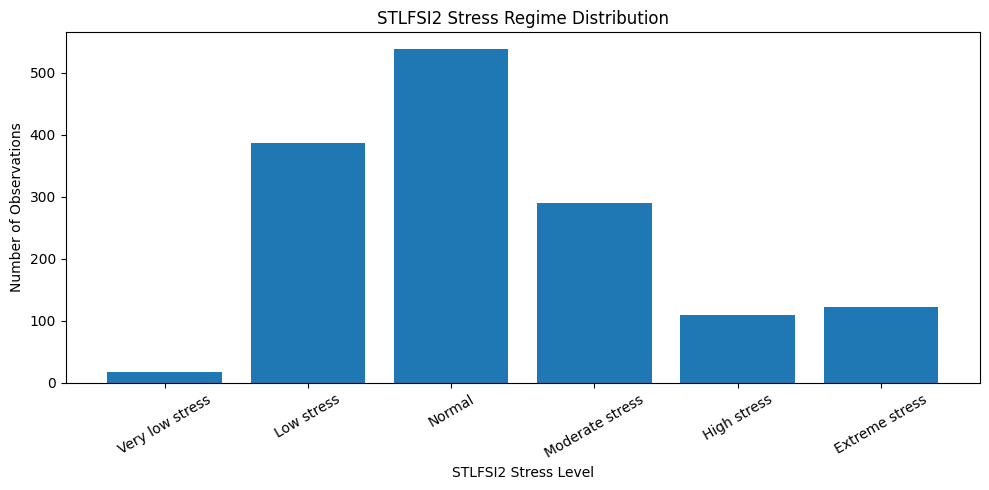

In [ ]:

# Define interpretable stress regimes
bins = [-np.inf, -1, -0.5, 0, 0.5, 1, np.inf]
labels = [
    "Very low stress",
    "Low stress",
    "Normal",
    "Moderate stress",
    "High stress",
    "Extreme stress"
]

df_stlfsi["stress_bucket"] = pd.cut(
    df_stlfsi["STLFSI2"],
    bins=bins,
    labels=labels
)

# Count and sort
bucket_counts = df_stlfsi["stress_bucket"].value_counts().sort_index()

#Visualization
plt.figure(figsize=(10, 5))
plt.bar(bucket_counts.index.astype(str), bucket_counts.values)
plt.xlabel("STLFSI2 Stress Level")
plt.ylabel("Number of Observations")
plt.title("STLFSI2 Stress Regime Distribution")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



As observed, these regime classifications can be used as control variables in subsequent analysis to test whether the relationship between real-time market microstructure variables and short-term price direction remains stable across different levels of financial stress. Importantly, the uneven distribution across stress levels shows that most observations cluster around normal and low-stress regimes, while extreme stress occurs rarely but with much larger magnitude. This justifies treating STLFSI2 primarily as a regime indicator rather than a continuously varying predictor. In the context of this project, these regimes allow us to test whether extremely short-term price direction for SPY responds differently under normal trading conditions versus periods of elevated systemic stress.

**Quality considerations**

The STLFSI2 dataset exhibits strong quality and suitability as a market regime indicator. The data spans a long time horizon (1993–2022) and covers multiple market cycles, including both tranquil periods and major financial crises. The clear separation between normal and stressed observations, as well as the heavy concentration of values in low to moderate stress ranges with rare extreme spikes, is economically intuitive and consistent with the episodic nature of systemic financial stress.

The stress buckets and decile ranges show well-defined and interpretable value intervals, allowing market conditions to be classified in a transparent and reproducible manner. Moreover, STLFSI2 is constructed by the Federal Reserve using publicly documented methodology and widely used financial indicators, which enhances its credibility and reliability for empirical research.

**Conclusion for STLFSI2**

Despite its strengths, STLFSI2 is a low-frequency, aggregate indicator and does not capture intraday or minute-level fluctuations in market stress. As a result, it cannot be interpreted as a real-time trading signal and may not reflect sudden stress changes occurring within a single trading session. Additionally, stressed periods are less frequent than normal periods, which may limit statistical power when analyzing extreme stress regimes.

These limitations are inherent to the nature of systemic stress indicators and do not undermine the role of STLFSI2 in this study. We mitigate them by using STLFSI2 strictly as a regime classification variable rather than a continuous predictor and by aligning it with high-frequency SPY data using date-based matching. The primary focus remains on how microstructure-based predictability differs across broad market regimes rather than on forecasting stress itself.

Overall, DS3 provides a reliable and theoretically appropriate control for market conditions and is well suited to complement the high-frequency order book and price data used in this project.

### DS4: The Chicago Fed National Financial Conditions Index (NFCI)

**Description.** The Chicago Fed National Financial Conditions Index (NFCI) measures broader financial conditions in the U.S. economy, including credit availability, leverage, and risk premia. It was initially explored as an alternative market regime indicator to STLFSI2 in order to assess whether different definitions of financial stress lead to materially different empirical results.

However, given the conceptual overlap between NFCI and STLFSI2 and the need to limit redundancy in control variables, NFCI is treated as a supplementary dataset rather than a primary input. The main analysis therefore relies on STLFSI2 as the sole financial stress indicator, with NFCI reserved for robustness checks if needed.

In DS4, we performed initial data profiling on the financial stress index dataset to examine its structure and quality. What we specifically looked for included: a date column (observation_date), a value column (NFCI), and any missing values or anomalous symbols—such as placeholder characters like periods (.) that might indicate null or unreported data. This foundational review ensured the dataset was appropriately formatted and free from obvious data entry issues before proceeding with deeper analysis.

In [59]:
ncfi_path = "sample_data/ds3_fred/NFCI.csv"
df_ncfi = pd.read_csv(ncfi_path)

print("Shape:", df_ncfi.shape)
print("Columns:", list(df_ncfi.columns))
display(df_ncfi.head())

Shape: (2871, 2)
Columns: ['observation_date', 'NFCI']


,observation_date,NFCI
0,1971-01-08,0.58728
1,1971-01-15,0.61906
2,1971-01-22,0.65598
3,1971-01-29,0.69657
4,1971-02-05,0.73956


Similar to DS3, we standardized and cleaned the data types by ensuring the date column was properly formatted as a `datetime` object and the value column as a `numeric` type. Following this, we sorted the dataset chronologically. This step was essential because a correctly typed and ordered time-series is a prerequisite for accurate time‑series plotting, date‑based filtering, and reliable calculations of temporal coverage (e.g., correct start and end dates). Without this cleaning, plots could misrepresent trends and summary statistics might incorrectly reflect the data's true time span.

In [60]:
df_ncfi["observation_date"] = pd.to_datetime(df_ncfi["observation_date"])
df_ncfi["NFCI"] = pd.to_numeric(df_ncfi["NFCI"], errors="coerce")

df_ncfi = df_ncfi.sort_values("observation_date").reset_index(drop=True)

print("Date range:", df_ncfi["observation_date"].min(), "to", df_ncfi["observation_date"].max())
print("Distinct dates:", df_ncfi["observation_date"].nunique())
print("Missing NFCI values:", df_ncfi["NFCI"].isna().sum())


Date range: 1971-01-08 00:00:00 to 2026-01-09 00:00:00
Distinct dates: 2871
Missing NFCI values: 0


As expected, NFCI here has broad historical coverage, but it’s a low-frequency macro-financial index, so it won’t move minute-to-minute and is not designed to reflect immediate trading conditions. We observe the value distribution for NCFI.

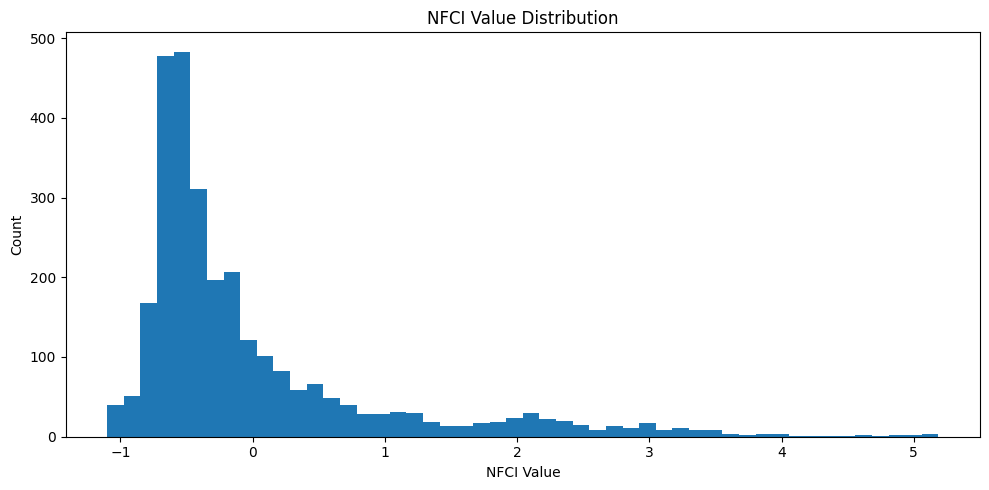

In [62]:
plt.figure(figsize=(10,5))
plt.hist(df_ncfi["NFCI"].dropna(), bins=50)
plt.xlabel("NFCI Value")
plt.ylabel("Count")
plt.title("NFCI Value Distribution")
plt.tight_layout()
plt.show()

Although NFCI spans a wide numerical range, the distribution is highly concentrated around a narrow central region (between -1 and +0.5), with extreme values occurring only during rare crisis episodes. This concentration indicates that NFCI varies slowly for most of the sample and primarily reflects broad financial conditions rather than real-time market stress relevant for extremely short-term price dynamics. We confirm this with the graph below which measures how often the index changes meaningfully from one period to the next. This tells us whether the index is sensitive to short‑term events or moves slowly over time, which is important for our project which is meant to predict 5-minute price movements.

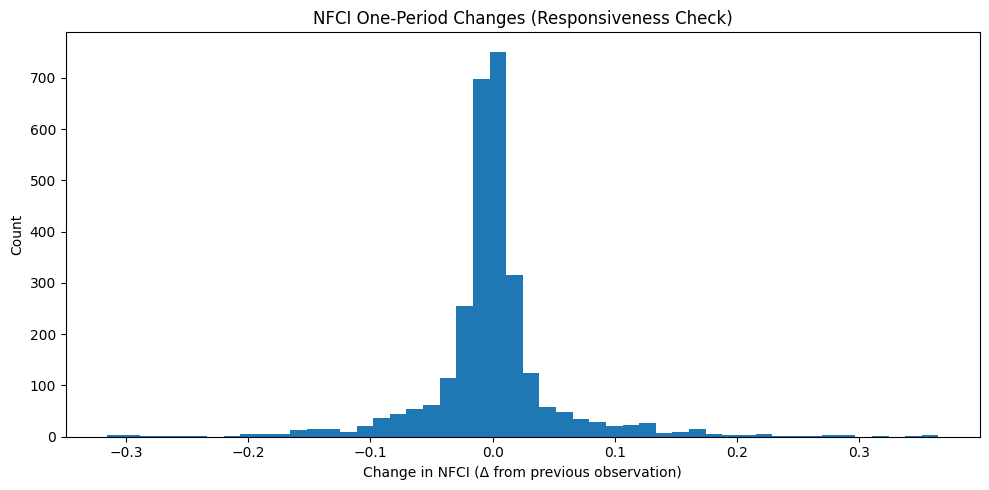

Std of changes (ΔNFCI): 0.05775913532615293
Median absolute change: 0.013399999999999995


In [73]:
df_ncfi["delta"] = df_ncfi["NFCI"].diff()

plt.figure(figsize=(10,5))
plt.hist(df_ncfi["delta"].dropna(), bins=50)
plt.xlabel("Change in NFCI (Δ from previous observation)")
plt.ylabel("Count")
plt.title("NFCI One-Period Changes (Responsiveness Check)")
plt.tight_layout()
plt.show()

print("Std of changes (ΔNFCI):", df_ncfi["delta"].std())
print("Median absolute change:", df_ncfi["delta"].abs().median())


The distribution of one-period changes in NFCI is sharply centered around zero, indicating that the index typically changes very little from one observation to the next. Most changes are small in magnitude, as reflected by the low median absolute change, while larger positive or negative shifts occur only rarely and form thin tails. This suggests that NFCI evolves smoothly over time and reacts slowly to changing market conditions, reinforcing its role as a broad, low-frequency indicator of financial conditions rather than a responsive measure of real-time market stress.

To assess whether NFCI provides information distinct from STLFSI2, we compute a rolling correlation between the two indices and visualize it as a heatmap. The results show that the correlation varies substantially over time, strengthening during major stress episodes but weakening during normal market conditions. This instability indicates that NFCI and STLFSI2 do not capture the same underlying dynamics consistently. Given our focus on market stress relevant for short-term price behavior, this supports the use of STLFSI2 as the primary regime indicator and the exclusion of NFCI from the main analysis.

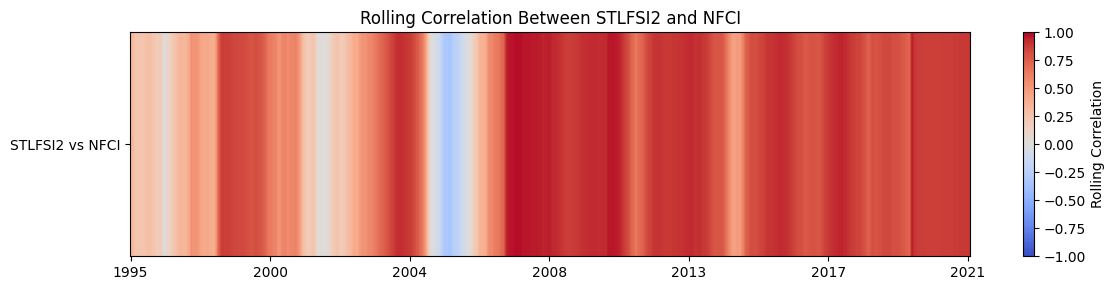

          STLFSI2      NFCI
STLFSI2  1.000000  0.876439
NFCI     0.876439  1.000000


In [74]:
# Merge NFCI and STLFSI2 on observation_date
df_both = pd.merge(
    df_stlfsi[["observation_date", "STLFSI2"]],
    df_ncfi[["observation_date", "NFCI"]],
    on="observation_date",
    how="inner"
)

df_both = df_both.sort_values("observation_date").reset_index(drop=True)


window = 104 

df_both["rolling_corr"] = (
    df_both["STLFSI2"]
    .rolling(window)
    .corr(df_both["NFCI"])
)

corr_series = df_both[["observation_date", "rolling_corr"]].dropna()
corr_series = corr_series.set_index("observation_date")

plt.figure(figsize=(12, 3))

plt.imshow(
    corr_series.T,
    aspect="auto",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Rolling Correlation")
plt.yticks([0], ["STLFSI2 vs NFCI"])

# Show a few year labels on x-axis
xticks = range(0, len(corr_series), max(1, len(corr_series)//6))
plt.xticks(xticks, corr_series.index[xticks].year)

plt.title("Rolling Correlation Between STLFSI2 and NFCI")
plt.tight_layout()
plt.show()

# Compute correlation matrix
corr_matrix = df_both[["STLFSI2", "NFCI"]].corr()
print(corr_matrix)



With most redness observed in the later years, we see that the correlation between the two indicators are incredibly high despite intended to capture different financial aspects. Computing the correlation between STLFSI2 and NFCI, we see that they have a correlation of 0.876439, making NFCI a redundant dataset.

**Data Quality Assessment for DS4:**

**Strength of STLFSI2**

STLFSI2 is specifically designed to capture financial market stress, not general economic conditions. Its components are heavily weighted toward:
- Equity market volatility
- Credit and funding market spreads
- Short-term funding stress and risk aversion

These are precisely the channels through which liquidity provision, order flow, and bid–ask dynamics change during stressed periods. As a result, STLFSI2 is well suited to classify regimes in which microstructure relationships may weaken, strengthen, or reverse, exactly what our hypothesis is testing.

Even though STLFSI2 is lower frequency than trading data, it operates at the right conceptual level: it separates normal trading environments from crisis-like conditions where extremely short-term predictability may behave differently.

**Weaknesses of NCFI**

NFCI measures broad financial conditions, including:
- Credit availability
- Leverage in the banking system
- Balance-sheet constraints

While these factors are important for macroeconomic and medium-term financial analysis, they are too slow-moving and structural for a study focused on minute-level price direction. NFCI is designed to reflect whether financial conditions are tight or loose in an economy-wide sense, not whether traders are currently facing heightened uncertainty or liquidity stress.

As a result:
- NFCI is less directly linked to intraday trading behavior
- Its variation is dominated by macro-financial trends, not market microstructure dynamics
- It is less likely to explain changes in short-term order flow or price impact

Using NFCI as a primary regime indicator would therefore introduce a mismatch between the time scale of the research question and the economic meaning of the variable.

**Conclusions for DS4:**

Both STLFSI2 and NFCI measure aspects of financial conditions, but they operate at different conceptual levels. For a study centered on extremely short-term price direction and real-time trading conditions in SPY, STLFSI2 provides a more direct, market-relevant definition of stress. NFCI was explored as an alternative measure but ultimately discarded because it reflects broader, slower-moving financial conditions that are less informative for high-frequency price formation.

This makes STLFSI2 the more appropriate and theoretically aligned choice for the project as compared to NCFI.

### DS5: Alpha Vantage Intraday Equity API

**Preamble:** In academic research, reproducibility requires verified data. The Kaggle SPY dataset (DS1), while comprehensive, lacks explicit documentation of curation, cleaning, and validation steps. To support robustness and transparency, we use the Alpha Vantage API as a quality assurance (QA) mechanism to spot-check DS1 prices and volumes over short validation windows. DS5 does not replace DS1 but complements it by providing an independent data source for targeted validation, particularly for identifying and filling small gaps.

**Description:** Alpha Vantage provides intraday equity price and volume data via REST API. We access the `TIME_SERIES_INTRADAY` endpoint for minute-level SPY data. Due to strict rate limits (5 requests/minute, 500 requests/day in the free tier), DS5 is applied selectively: we validate representative periods (e.g., 1 week per year across the DS1 span) rather than attempting full-period replacement. For each validation window, we cross-check:
- **Price consistency**: Compare OHLC bars from Kaggle vs API (tolerance: ±$0.01)
- **Volume alignment**: Verify trading volume within ±2% relative difference
- **Timestamp integrity**: Confirm no missing bars during regular trading hours

| Metric | Value | Interpretation |
|--------|-------|----------------|
| **API Rate Limit** | 5 calls/minute | Constrains coverage (selective only) |
| **Pricing Format** | 1-minute OHLCV (matches DS1) | Perfect temporal alignment |
| **Cost** | Free tier is used but premium available | Budget-friendly validation |
| **Latency** | ~5 min delay | Adequate for end-of-day reconciliation |

Alpha Vantage returns JSON-formatted minute-bar data with Open, High, Low, Close, Volume. The API is widely used in industry and academia and has higher transparency in its data sourcing (FCSAPI feeds). Validation through DS5 increases confidence in DS1 for downstream analysis.

**Exploratory steps**

We used Alpha Vantage’s free tier, which restricts us to 5 requests per minute and 500 per day. This allowed us to collect roughly 1–2 months of 1‑minute data, not the full period. We accepted this gap in coverage to validate data patterns without exceeding API limits.

In [77]:
# This function calls the Alpha Vantage API to retrieve historical daily data
def get_historical_stock_data(symbol):

    base_url = "https://www.alphavantage.co/query"
    params = {
        "function": "TIME_SERIES_DAILY_ADJUSTED",
        "symbol": symbol,
        "outputsize": "full",         
        "apikey": "TO_BE_INSERTED"
    }

    try:
        response = requests.get(base_url, params=params)
        response.raise_for_status()  # Raise error for bad responses
        data = response.json()
        return data

    except requests.exceptions.RequestException as e:
        print(f"Error retrieving stock data: {e}")
        return None

We restrict our data retrieval to a targeted subset of variables so that missing values can be filled within a reasonable time during the data preparation stage. Rather than attempting to download many endpoints or repeatedly query large date ranges, we prioritize only the fields that are both (i) missing in our existing dataset and (ii) directly returned by Alpha Vantage.

In addition, we only consider features that Alpha Vantage provides at the required frequency. For our project on extremely short-term SPY price direction, this means focusing on core market variables that Alpha Vantage reliably returns (e.g., open/high/low/close, volume, and, depending on endpoint, adjusted close). Over time, we retrieved additional observations for specific timestamps where our existing data was missing or incomplete. Upon comparing the newly collected Alpha Vantage values with our primary sources, we observe that price-based fields (OHLC) are generally consistent in scale and direction, but volume and timestamp alignment can differ due to differences in reporting conventions (e.g., timezone, aggregation rules, or adjustments). This means the Alpha Vantage data is most useful for completing missing OHLC-type price information, while fields that are more sensitive to vendor-specific definitions (especially volume or adjusted fields) require extra caution.

**Quality considerations:**  
From the exploration and cross-checking process, we make the following observations regarding data quality:
- Completeness: Alpha Vantage provides broad historical coverage for standard OHLC fields, making it useful for filling gaps when our primary dataset has missing price observations. However, completeness at very high frequency may be limited by endpoint constraints and rate limits, so targeted retrieval is necessary.
- Consistency / comparability: Price series are largely comparable to our existing sources, but volume and exact timestamp alignment may differ depending on Alpha Vantage’s aggregation rules and time conventions. Therefore, Alpha Vantage is more reliable for completing missing price levels than for validating microstructure-level quantities.

**Concluding discussion:**  
Overall, Alpha Vantage is useful for our application, but mainly as a supplementary data source rather than a primary one. Due to API rate limits, we restrict retrieval to a small set of key price variables where missingness is limited and the benefit of completion is highest. In practice, the most consistent and actionable contribution of Alpha Vantage is filling missing OHLC-style price data (and possibly adjusted close where relevant), while more vendor-sensitive fields such as volume require additional validation and may be excluded from critical analysis steps. As a result, we retain Alpha Vantage as a targeted tool for gap-filling and cross-validation, while continuing to rely on our primary high-frequency datasets for the core microstructure analysis.

#### Datasets Not Included and Reasons for not Including

In our exploration phase, we considered multiple datasets, but ultimately did not go with them. These are the additional candidates we evaluated and their reasons:

**Alternative Price Sources (e.g., Yahoo Finance, IEX Cloud)**  
Exclusion Rationale: While these sources provide similar SPY historical data, they introduce data versioning conflicts without adding analytical value. The Kaggle SPY dataset (DS1) provides complete OHLCV coverage from 2008-2021 with consistent formatting. Adding parallel price feeds would create synchronization complexity and validation overhead (matching timestamps, adjusting for splits/dividends), all while providing identical price series information, violating data minimization principles.

**Volatility Indices (e.g., VIX)**  
Exclusion Rationale: VIX is a derived, not direct, market measure, calculated from S&P 500 options prices, not actual equity trading. This creates a theoretical mismatch: VIX reflects investor expectations about future volatility (a "fear gauge"), while we're modeling actual liquidity and price dynamics in SPY. Furthermore, VIX exhibits different statistical properties (mean-reverting, range-bound) that would require specialized handling, potentially diluting our microstructure focus. The FRED financial stress indices (DS3) provide more directly comparable, economically-grounded measures.

**Trade Tick Data (Individual Orders)**  
Exclusion Rationale: Trade-level data provides excessive granularity for our 5-minute prediction horizon, creating a resolution mismatch. Processing every trade would require orders of magnitude more computation (terabytes vs gigabytes) while offering diminishing returns, and most individual trades are noise, not signal. The LOBSTER limit order book data (DS2) already captures the essential microstructure state (bid-ask spreads, order imbalance) at discrete snapshots, providing the relevant liquidity signals without computational bloat.

**Additional Macroeconomic Variables (e.g., Interest Rates, Inflation)**  
Exclusion Rationale: These represent competing explanatory frameworks that would create feature redundancy and multicollinearity. Interest rates and inflation operate on different time scales (monthly/quarterly) than our intraday predictions, creating temporal misalignment. More critically, they would confound the regime identification we derive from FRED's NFCI/STLFSI indices, which already synthesize multiple macroeconomic factors into unified stress metrics. Adding component variables would violate the structure of our analysis.